# Exercise 29 – Linear regression with ordinary least squares

**Week 6 · Regression**

A model that is *linear in its parameters*, $f(x) = \sum_j \beta_j\,\phi_j(x)$,
can be fitted in closed form. With the design matrix $X_{ij} = \phi_j(x_i)$,
the least-squares solution is

$$\boldsymbol\beta = (X^TX)^{-1}X^T\mathbf y .$$

Here the basis functions are powers, $\phi_j(x) = x^j$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.plotting import setup_axes
from comphy.regression import PolynomialRegression

## A straight line
Five points on $y = -2x + 3$ are fitted exactly by the basis $\{1, x\}$.

coefficients (intercept, slope): [ 3. -2.]


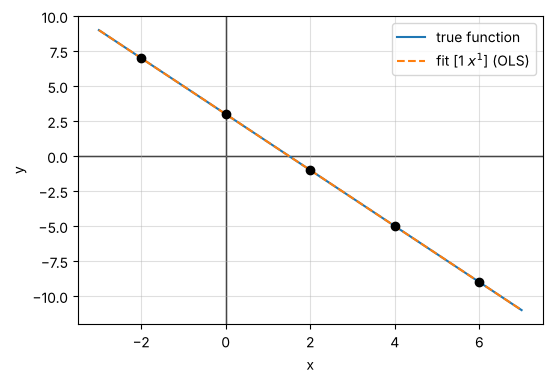

In [2]:
f = lambda x: -2 * x + 3
x_data = np.array([-2, 0, 2, 4, 6])
model = PolynomialRegression([0, 1]).fit(x_data, f(x_data))
print("coefficients (intercept, slope):", model.beta.round(6))

xs = np.linspace(-3, 7, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xs, f(xs), label="true function")
ax.plot(xs, model.predict(xs), "--", label=f"fit {model.label()}")
ax.scatter(x_data, f(x_data), color="black", zorder=3)
setup_axes(ax)
ax.legend()
plt.show()

## A curved target
$f(x) = \tfrac12 x\sin x + \tfrac34$ sampled at five points. With five points
a polynomial of degree 4 (five coefficients) passes exactly through all of
them; more coefficients than data points would make $X^TX$ singular.

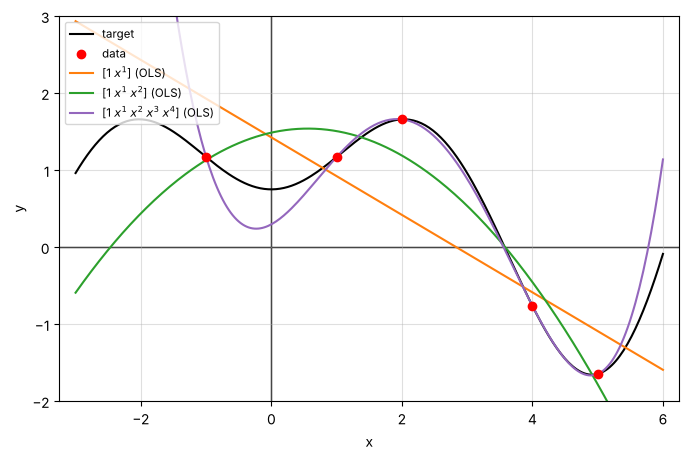

In [3]:
f = lambda x: 0.5 * x * np.sin(x) + 0.75
x_data = np.array([-1, 1, 2, 4, 5])
xs = np.linspace(-3, 6, 300)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs, f(xs), color="black", label="target")
ax.scatter(x_data, f(x_data), color="red", zorder=3, label="data")
for degree, color in [(1, "C1"), (2, "C2"), (4, "C4")]:
    model = PolynomialRegression(range(degree + 1)).fit(x_data, f(x_data))
    ax.plot(xs, model.predict(xs), color=color, label=model.label())
setup_axes(ax, xlim=(-3.25, 6.25), ylim=(-2, 3))
ax.legend(fontsize="small", loc="upper left")
plt.show()

The interpolating degree-4 polynomial goes through every point but
oscillates between and beyond them – a first taste of overfitting.